> **In this repository.** Writes the BioCLIP 2 candidates in the same run format as the fine-tuning notebooks so they enter the model comparison. Its zero-shot-full candidate is one of the project's two final models. It was run on Google Colab against the team's Google Drive, so its paths point to Drive; the saved outputs are the record of what it produced. To re-run it from this repository, change the data path to the folder made by `src/invasive_clf/data/download_images.py` (see `data/README.md`).

# 16. BioCLIP 2 final candidates, in the team's run format

BioCLIP 2 enters the model comparison through the **same pipeline as every other backbone**: the same image cache (`Resize(256)`, `CenterCrop(224)`), the same BioCLIP 2 adapter (`build_open_clip("imageomics/bioclip-2")`, projected 768-d features), the same metric code, threshold rule and mirror-image averaging, and the same run files (`config.json`, `history.csv`, `metrics_final.json`, `val_predictions.csv`, `decisions.json`, `best.joblib`, plots). Sections 0-5 are **copied unchanged from the benchmark notebook `17_logreg_baselines.ipynb`**.

Four candidates, all on the frozen BioCLIP 2 image tower (nothing is fine-tuned):

| family (folder in `modeling_runs/`) | method | uses names? | uses train photos? |
|---|---|---|---|
| `logreg_bioclip2` | the benchmark one-vs-all logistic regression, run with the benchmark's own `run_baseline` | no | yes |
| `bioclip2_knn` | k-nearest neighbours, similarity-weighted vote over the 41 labels | no | yes |
| `bioclip2_zeroshot_full` | zero-shot over the full 4,573-name vocabulary (441 classes + 4,132 regional species) | yes | no |
| `bioclip2_knn_zeroshot_full` | weighted average of the kNN and zero-shot-full probabilities | yes | yes |

Section 12 then rehearses **unknown species** on val for every candidate (same random draws as notebook 15), because the candidates are expected to be within val noise of each other on macro-F1 and differ mainly there.

Uses `train.csv`, `val.csv`, `classes.csv` and notebook 14's saved text embeddings. **Never touches `test.csv` or `test_unseen.csv`.** Needs a GPU runtime (ViT-L/14 feature extraction). Run it from the account that can write to the team's `modeling_runs`.

**To include these runs in `18_final_model_comparison.ipynb`** (its Section 1): add `"bioclip2": {"display": "BioCLIP 2 ViT-L/14", "arch": "ViT", "params_M": 304, "pretraining": "BioCLIP 2 image-text (TreeOfLife-200M)"}` to `BACKBONES`, and set `INCLUDE_OTHER_FAMILIES = True`. With only the first change, `logreg_bioclip2` competes as a linear probe and the other three are shown for context.

## 0. Environment

In [1]:
import importlib.util, os, subprocess, sys

IN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content")

# Install what is missing (Colab ships torch/torchvision/sklearn/pandas/matplotlib already).
_required = {"torchmetrics": "torchmetrics", "timm": "timm", "huggingface_hub": "huggingface_hub",
             "transformers": "transformers>=4.57.3", "open_clip": "open_clip_torch"}
_missing = [pkg for mod, pkg in _required.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

# DINOv3 needs transformers >= 4.57.3 (PlantNet's own requirements.txt). Upgrade if the class is absent.
import transformers
if importlib.util.find_spec("transformers.models.dinov3_vit") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", "transformers>=4.57.3"])
    print("transformers upgraded; RESTART THE RUNTIME and run again.")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import copy, datetime, json, math, random, re, shutil, time, warnings
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from torchvision.transforms import v2
import torchmetrics
from torchmetrics.classification import MulticlassF1Score, MulticlassAccuracy, MulticlassConfusionMatrix
from tqdm.auto import tqdm
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
                             precision_score, recall_score, f1_score)
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
import joblib

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if (DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()) else torch.float16
print(f"torch {torch.__version__} | transformers {transformers.__version__} | torchmetrics {torchmetrics.__version__}")
print(f"device: {DEVICE} | mixed-precision dtype: {AMP_DTYPE if DEVICE.type == 'cuda' else 'disabled (CPU)'}")
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GiB")

# Plot style shared by every notebook so figures are comparable across models.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
C_BLUE, C_ORANGE, C_GRAY = "#2a78d6", "#eb6834", "#9a9995"

def seed_everything(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

torch 2.11.0+cu130 | transformers 5.22.0 | torchmetrics 1.9.0
device: cuda | mixed-precision dtype: torch.bfloat16
Tesla T4 14.6 GiB


## 1. Configuration

`BASE_CONFIG` applies to every backbone. A backbone cell in Section 6 can pass a `dict` of overrides (same keys), which is recorded in that run's `config.json`.

In [3]:
# Leave both as None to use the Team Drive path on Colab or the repo-relative path locally.
DATA_ROOT_OVERRIDE = None                    # e.g. "/path/to/downloaded_data/inat_dataset_final"
RUNS_DIR_OVERRIDE = None                     # e.g. "/path/to/modeling_runs"; default: <repo root>/modeling_runs

BASE_CONFIG = {
    # --- input: the deterministic eval transform of the fine-tuning notebooks, used for train and val alike ---
    "image_size": 224,
    "val_resize": 256,                        # Resize(shorter side) then CenterCrop(image_size)
    "batch_size": 128,                        # feature extraction only (no backward pass); reduce if the GPU runs out of memory
    "num_workers": 2,
    "amp": True,                              # mixed precision for the feature extraction
    "backbone_kwargs": {},                    # adapter defaults: DINOv3 "cls" pooling, BioCLIP projected features, no drop path
    # --- one-vs-all logistic regression over the invasive classes ---
    "standardize": True,                      # StandardScaler fit on the train embeddings
    "C_grid": [1e-3, 3e-3, 1e-2, 3e-2, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0],   # inverse L2 strength; chosen on validation
    "class_weight": None,                     # None = plain logistic loss (like the fine-tuned baseline's plain BCE); or "balanced"
    "max_iter": 5000,                         # lbfgs iterations per binary problem
    # --- evaluation ---
    "threshold_grid": [round(t, 3) for t in np.linspace(0.01, 0.99, 99)],
    "select_metric": "macro_f1_invasive",     # C selection + threshold tuning target
    "tta_hflip": True,                        # final evaluation averages the probabilities of each val image and its mirror
    # --- bookkeeping ---
    "seed": 42,
}

## 2. Paths and data

The dataset folder is `DATA_ROOT_OVERRIDE` if set, else the Team Drive path on Colab, else the repo-relative path. Only `train.csv` and `val.csv` are read. The last cell of this section decodes every image once into RAM as a centre crop (about 1.6 GB); every backbone extracts its features from that cache, so the images are read from Drive a single time per kernel.

In [4]:
_candidates = [DATA_ROOT_OVERRIDE,
               "/content/drive/MyDrive/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_final",
               "/content/drive/Shareddrives/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_final",
               "../../downloaded_data/inat_dataset_final", "downloaded_data/inat_dataset_final"]
DATA_ROOT = next((Path(p) for p in _candidates if p and (Path(p) / "train.csv").exists()), None)
assert DATA_ROOT is not None, f"dataset folder not found; tried {_candidates}"
RUNS_DIR = Path(RUNS_DIR_OVERRIDE) if RUNS_DIR_OVERRIDE else DATA_ROOT.parent.parent / "modeling_runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)
print("DATA_ROOT:", DATA_ROOT.resolve()); print("RUNS_DIR:", RUNS_DIR.resolve())

NONE_LABEL = "not_invasive"
train_df = pd.read_csv(DATA_ROOT / "train.csv")
val_df = pd.read_csv(DATA_ROOT / "val.csv")

INVASIVE_CLASSES = sorted(c for c in train_df["label"].unique() if c != NONE_LABEL)
N_INVASIVE = len(INVASIVE_CLASSES)
CLASS_TO_IDX = {c: i for i, c in enumerate(INVASIVE_CLASSES)}
CLASS_TO_IDX[NONE_LABEL] = N_INVASIVE                   # index N_INVASIVE = not_invasive (no logit, only a target)
ALL_LABELS = INVASIVE_CLASSES + [NONE_LABEL]            # 41 names in index order
assert set(val_df["label"]) <= set(ALL_LABELS), "val has labels that train does not"
assert not set(train_df["observer_id"]) & set(val_df["observer_id"]), "observer leakage between train and val"

for name, df in (("train", train_df), ("val", val_df)):
    df["y"] = df["label"].map(CLASS_TO_IDX)
    print(f"{name}: {len(df):>5} rows | {df['invasive'].sum():>4} invasive | {(~df['invasive']).sum():>4} {NONE_LABEL} | "
          f"{df.loc[df['invasive'], 'label'].nunique()} invasive classes, {df['scientific_name'].nunique()} species")
print(f"{N_INVASIVE} invasive classes -> {N_INVASIVE} logits; '{NONE_LABEL}' is the all-zero target (index {N_INVASIVE})")

DATA_ROOT: /content/drive/.shortcut-targets-by-id/1VxedFijuaqDrUGWdycVJebTUGmt3qkqk/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_final
RUNS_DIR: /content/drive/.shortcut-targets-by-id/1VxedFijuaqDrUGWdycVJebTUGmt3qkqk/fall-2026-DL-invasive-plants/modeling_runs
train:  7342 rows | 1186 invasive | 6156 not_invasive | 40 invasive classes, 441 species
val:  3228 rows |  982 invasive | 2246 not_invasive | 40 invasive classes, 441 species
40 invasive classes -> 40 logits; 'not_invasive' is the all-zero target (index 40)


In [5]:
# Check which image files exist (the download may have gaps; see download_failures.csv).
_failures_file = DATA_ROOT / "download_failures.csv"
if _failures_file.exists():
    try:
        _f = pd.read_csv(_failures_file)
        print(f"download_failures.csv: {len(_f)} rows")
    except pd.errors.EmptyDataError:                 # the download cell writes an empty file when nothing failed
        print("download_failures.csv exists but is empty: no failed downloads")

for name, df in (("train", train_df), ("val", val_df)):
    df["exists"] = df["image_path"].map(lambda p: (DATA_ROOT / p).is_file())
    n_missing = (~df["exists"]).sum()
    if n_missing:
        missing_by_class = df.loc[~df["exists"], "label"].value_counts()
        print(f"{name}: {n_missing} rows without an image file (dropped). Worst classes:\n{missing_by_class.head(8).to_string()}")
    else:
        print(f"{name}: all {len(df)} image files present")
train_df = train_df[train_df["exists"]].reset_index(drop=True)
val_df = val_df[val_df["exists"]].reset_index(drop=True)
assert len(train_df) and len(val_df), "no images found under DATA_ROOT; is Drive mounted / are the images downloaded?"

download_failures.csv exists but is empty: no failed downloads
train: all 7342 image files present
val: all 3228 image files present


In [6]:
# Decode every train/val image ONCE into RAM as uint8 centre crops: Resize(val_resize) -> CenterCrop(image_size).
# Reading 10k small files from a mounted Drive is slow (tens of minutes), so it is done a single time per kernel and every
# backbone below extracts its features from these tensors. Nothing is written to disk.


class _Decode(Dataset):
    # one-off decode + deterministic transform; wrapped in a DataLoader only to use several worker processes
    def __init__(self, paths, tf):
        self.paths, self.tf = list(paths), tf

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = ImageOps.exif_transpose(Image.open(DATA_ROOT / self.paths[i])).convert("RGB")
        return T.functional.pil_to_tensor(self.tf(img))                  # uint8, C x H x W


def decode_all(paths, tf, desc):
    dl = DataLoader(_Decode(paths, tf), batch_size=None, num_workers=BASE_CONFIG["num_workers"],
                    generator=torch.Generator().manual_seed(0))                                     # do not touch the global RNG
    return torch.stack([t for t in tqdm(dl, total=len(paths), desc=desc, unit="img", leave=False)])


EVAL_TF = T.Compose([T.Resize(BASE_CONFIG["val_resize"]), T.CenterCrop(BASE_CONFIG["image_size"])])
t0 = time.time()
TRAIN_IMAGES = decode_all(train_df["image_path"], EVAL_TF, "decoding train images")
VAL_IMAGES = decode_all(val_df["image_path"], EVAL_TF, "decoding val images")
print(f"image cache: {len(TRAIN_IMAGES)} train + {len(VAL_IMAGES)} val centre crops of {BASE_CONFIG['image_size']}x{BASE_CONFIG['image_size']} = "
      f"{(TRAIN_IMAGES.numel() + VAL_IMAGES.numel()) / 2**30:.2f} GB in RAM ({time.time() - t0:.0f}s)")

decoding train images:   0%|          | 0/7342 [00:00<?, ?img/s]

decoding val images:   0%|          | 0/3228 [00:00<?, ?img/s]

image cache: 7342 train + 3228 val centre crops of 224x224 = 1.48 GB in RAM (2189s)


## 3. Backbone adapters

A backbone adapter returns a `BackboneSpec`: an `nn.Module` whose `forward(x)` maps a normalized image batch to the **native pooled feature vector**, plus the feature dimension and the normalization constants of the checkpoint. Identical to the fine-tuning notebooks; here the backbone stays frozen and its pooled features feed the logistic regression.

Adapters read `cfg["backbone_kwargs"]` for model-specific options. Implemented: the PlantNet DINOv3 ViT-S/16 and the plain DINOv3 ViT-S/16 (`pooling`, `drop_path_rate`); BioCLIP (ViT-B/16) and BioCLIP 2 (ViT-L/14) through `open_clip` (`features`: the projected CLIP image embedding, or the wider pre-projection token); SigLIP 2 ViT-B/16 and any other `timm` checkpoint (ResNet-18/50, ConvNeXt-Tiny; `drop_path_rate` where the architecture has it). `layer_decay` understands the block naming of all of them (`layer.N`, `blocks.N`, `resblocks.N`).

In [7]:
@dataclass
class BackboneSpec:
    module: nn.Module          # forward(x) -> (B, feat_dim) pooled features
    feat_dim: int
    mean: tuple                # normalization of the checkpoint
    std: tuple
    notes: str = ""

IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


class HFPooledBackbone(nn.Module):
    # Wraps a HF vision model. pooling="cls": .pooler_output (DINOv3: final-normed CLS token).
    # pooling="cls+patchmean": CLS concatenated with the mean of the patch tokens (skips CLS + register tokens).
    def __init__(self, hf_model, pooling="cls", n_prefix_tokens=1):
        super().__init__(); self.m = hf_model; self.pooling = pooling; self.n_prefix = n_prefix_tokens
        assert pooling in ("cls", "cls+patchmean"), pooling
    def forward(self, x):
        out = self.m(pixel_values=x)
        if self.pooling == "cls":
            return out.pooler_output
        return torch.cat([out.pooler_output, out.last_hidden_state[:, self.n_prefix:].mean(1)], dim=1)


def build_plantnet_dinov3_vits(cfg) -> BackboneSpec:
    # PlantNet/plantnet-300k-v2-vits: DINOv3 ViT-S/16 encoder + 1000-way head in model.pth.
    # We rebuild the encoder architecture from config (ViT-S/16 with 4 register tokens; verified to load with
    # strict=True) so the gated facebook/dinov3-* weights are NOT needed; the encoder weights come from model.pth.
    # The 1000-class Pl@ntNet head is discarded.
    from huggingface_hub import snapshot_download
    from transformers import DINOv3ViTConfig, DINOv3ViTModel
    repo = snapshot_download("PlantNet/plantnet-300k-v2-vits", allow_patterns=["model.pth", "plantnet_config.json"])
    pn_cfg = json.load(open(Path(repo) / "plantnet_config.json"))
    ckpt = torch.load(Path(repo) / "model.pth", map_location="cpu", weights_only=True)
    bk = cfg.get("backbone_kwargs", {})
    pooling, drop_path = bk.get("pooling", "cls"), bk.get("drop_path_rate", 0.0)
    encoder = DINOv3ViTModel(DINOv3ViTConfig(hidden_size=384, num_hidden_layers=12, num_attention_heads=6,
                                             intermediate_size=1536, patch_size=16, num_register_tokens=4,
                                             image_size=cfg["image_size"], drop_path_rate=drop_path))
    encoder.load_state_dict(ckpt["encoder"], strict=True)
    feat_dim = pn_cfg["embedding_dim"] * (2 if pooling == "cls+patchmean" else 1)
    return BackboneSpec(HFPooledBackbone(encoder, pooling, n_prefix_tokens=1 + 4), feat_dim, tuple(pn_cfg["image_mean"]),
                        tuple(pn_cfg["image_std"]),
                        notes=f"PlantNet-300K-v2 fine-tuned DINOv3 ViT-S/16; PlantNet mean/std; pooling={pooling}, drop_path={drop_path}")


def build_dinov3_vits16(cfg) -> BackboneSpec:
    # Plain DINOv3 ViT-S/16 (self-supervised, LVD-1689M). Gated: accept the license on HF and `huggingface-cli login`.
    from transformers import AutoModel
    enc = AutoModel.from_pretrained("facebook/dinov3-vits16-pretrain-lvd1689m")
    pooling = cfg.get("backbone_kwargs", {}).get("pooling", "cls")
    feat_dim = enc.config.hidden_size * (2 if pooling == "cls+patchmean" else 1)
    return BackboneSpec(HFPooledBackbone(enc, pooling, 1 + enc.config.num_register_tokens), feat_dim, IMAGENET_MEAN, IMAGENET_STD,
                        notes=f"DINOv3 ViT-S/16, ImageNet mean/std, pooling={pooling}")


class TimmBackbone(nn.Module):
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, x):
        return self.m(x)                       # num_classes=0 -> pooled features


def build_timm(timm_name):
    # Any timm checkpoint, e.g. "resnet18.a1_in1k", "resnet50.a1_in1k", "convnext_tiny.fb_in22k_ft_in1k",
    # "vit_base_patch16_siglip_224.v2_webli" (the SigLIP 2 ViT-B/16 image tower with its attention-pooling head, 768-d).
    # backbone_kwargs["drop_path_rate"] is passed through when set (ViTs, ConvNeXt; ResNets ignore it).
    def _build(cfg) -> BackboneSpec:
        import timm
        drop_path = cfg.get("backbone_kwargs", {}).get("drop_path_rate", 0.0)
        kw = {"drop_path_rate": drop_path} if drop_path else {}
        m = timm.create_model(timm_name, pretrained=True, num_classes=0, **kw)   # drops the pretraining head, keeps the pooling
        dc = timm.data.resolve_data_config({}, model=m)
        return BackboneSpec(TimmBackbone(m), m.num_features, tuple(dc["mean"]), tuple(dc["std"]),
                            notes=f"timm {timm_name}, pool={getattr(m, 'global_pool', '?')}, drop_path={drop_path}")
    return _build


class OpenClipVisual(nn.Module):
    # The image tower of an open_clip model. features="projected": the CLIP image embedding that the contrastive loss was
    # trained on (BioCLIP 512-d, BioCLIP 2 768-d); features="pre_proj": the pooled CLS token after ln_post, before the
    # projection (768-d / 1024-d). open_clip skips the projection when visual.proj is None.
    def __init__(self, visual, features="projected"):
        super().__init__(); assert features in ("projected", "pre_proj"), features
        self.m = visual
        if features == "pre_proj":
            self.m.proj = None
    def forward(self, x):
        return self.m(x)


def build_open_clip(hf_repo):
    # BioCLIP (imageomics/bioclip: ViT-B/16, TreeOfLife-10M) and BioCLIP 2 (imageomics/bioclip-2: ViT-L/14, TreeOfLife-200M)
    # are open_clip checkpoints on the HF hub (not gated). The text tower is loaded and discarded.
    def _build(cfg) -> BackboneSpec:
        import open_clip
        features = cfg.get("backbone_kwargs", {}).get("features", "projected")
        clip = open_clip.create_model(f"hf-hub:{hf_repo}")
        visual = clip.visual; del clip
        mean = tuple(getattr(visual, "image_mean", None) or open_clip.OPENAI_DATASET_MEAN)
        std = tuple(getattr(visual, "image_std", None) or open_clip.OPENAI_DATASET_STD)
        feat_dim = visual.output_dim if features == "projected" else visual.transformer.width
        return BackboneSpec(OpenClipVisual(visual, features), feat_dim, mean, std,
                            notes=f"{hf_repo} image tower (open_clip), CLIP mean/std, features={features}")
    return _build


BACKBONE_REGISTRY = {
    "plantnet_dinov3_vits": build_plantnet_dinov3_vits,
    "dinov3_vits16": build_dinov3_vits16,
    "resnet18": build_timm("resnet18.a1_in1k"),
    "resnet50": build_timm("resnet50.a1_in1k"),
    "convnext_tiny": build_timm("convnext_tiny.fb_in22k_ft_in1k"),
    "bioclip": build_open_clip("imageomics/bioclip"),                        # ViT-B/16, 86M params, 512-d embedding
    "bioclip2": build_open_clip("imageomics/bioclip-2"),                     # ViT-L/14, 304M params, 768-d embedding
    "siglip2_base": build_timm("vit_base_patch16_siglip_224.v2_webli"),      # SigLIP 2 ViT-B/16, 93M params, 768-d MAP features
}
print("registered backbones:", list(BACKBONE_REGISTRY))

registered backbones: ['plantnet_dinov3_vits', 'dinov3_vits16', 'resnet18', 'resnet50', 'convnext_tiny', 'bioclip', 'bioclip2', 'siglip2_base']


## 4. Metrics (identical in every model notebook)

Inputs: `probs` of shape `(N, N_INVASIVE)` = the one-vs-all probabilities, and `y` in `0..N_INVASIVE` (`N_INVASIVE` = `not_invasive`).

| metric | definition |
|---|---|
| `macro_ap_invasive` | mean over the invasive classes of average precision (one-vs-rest, threshold-free) |
| `top1_recall_invasive`, `top3_recall_invasive` | among rows whose true label is invasive: is the true class the top-1 / within the top-3 ranked logits (threshold-free) |
| `threshold` | value of `t` on `threshold_grid` maximising `macro_f1_invasive` on the validation set |
| `macro_f1_invasive` | **primary validation metric**: per-class F1 of the 41-way prediction (`argmax` if `max prob >= t` else `not_invasive`), averaged over the invasive classes only, computed on all rows |
| `top1_acc_all` | **primary KPI**: accuracy of the 41-way prediction over all rows |
| `bin_precision_invasive`, `bin_recall_invasive`, `bin_f1_invasive`, `bin_ap_invasive`, `bin_auroc_invasive` | binary "invasive vs not" with score `max prob` and threshold `t` |
| `noninv_precision`, `noninv_recall`, `noninv_auroc` | the same binary problem seen from the `not_invasive` side (positive = not invasive, score `1 - max prob`) |
| `per_class_f1`, `per_class_ap`, `confusion_matrix` | arrays for the plots and for `metrics_final.json` |

In [8]:
def predict_not_invasive(probs: np.ndarray, t: float) -> np.ndarray:
    # Species when the strongest invasive probability clears t, otherwise not_invasive.
    pred = probs.argmax(1)
    pred[probs.max(1) < t] = N_INVASIVE
    return pred


def macro_f1_invasive(y: np.ndarray, pred: np.ndarray) -> float:
    f1 = MulticlassF1Score(num_classes=N_INVASIVE + 1, average=None)(torch.as_tensor(pred), torch.as_tensor(y))
    return float(f1[:N_INVASIVE].mean())


def tune_threshold(probs, y, grid):
    # Sweep the grid; return the best t plus the full sweep for plotting.
    sweep = pd.DataFrame({"threshold": grid})
    sweep["macro_f1_invasive"] = [macro_f1_invasive(y, predict_not_invasive(probs, t)) for t in grid]
    sweep["top1_acc_all"] = [float((predict_not_invasive(probs, t) == y).mean()) for t in grid]
    best = sweep.loc[sweep["macro_f1_invasive"].idxmax()]
    return float(best["threshold"]), sweep


def compute_metrics(probs: np.ndarray, y: np.ndarray, threshold: float | None, grid) -> dict:
    probs = np.asarray(probs, dtype=np.float64); y = np.asarray(y)
    is_inv = y < N_INVASIVE
    onehot = np.eye(N_INVASIVE + 1)[y][:, :N_INVASIVE]              # (N, N_INVASIVE) binary targets

    m = {}
    # threshold-free, ranking metrics over the invasive classes
    per_class_ap = np.array([average_precision_score(onehot[:, c], probs[:, c]) if onehot[:, c].any() else np.nan
                             for c in range(N_INVASIVE)])
    m["macro_ap_invasive"] = float(np.nanmean(per_class_ap))
    if is_inv.any():
        rank = (-probs[is_inv]).argsort(1)
        m["top1_recall_invasive"] = float((rank[:, 0] == y[is_inv]).mean())
        m["top3_recall_invasive"] = float((rank[:, :3] == y[is_inv, None]).any(1).mean())
    # threshold
    sweep = None
    if threshold is None:
        threshold, sweep = tune_threshold(probs, y, grid)
    m["threshold"] = float(threshold)
    pred = predict_not_invasive(probs, threshold)
    # 41-way metrics at the fixed threshold
    f1_per_class = MulticlassF1Score(num_classes=N_INVASIVE + 1, average=None)(torch.as_tensor(pred), torch.as_tensor(y)).numpy()
    m["macro_f1_invasive"] = float(f1_per_class[:N_INVASIVE].mean())
    m["macro_f1_all41"] = float(f1_per_class.mean())
    m["top1_acc_all"] = float(MulticlassAccuracy(num_classes=N_INVASIVE + 1, average="micro")(torch.as_tensor(pred), torch.as_tensor(y)))
    # binary invasive detection
    score_inv = probs.max(1); pred_inv = pred < N_INVASIVE
    m["bin_precision_invasive"] = precision_score(is_inv, pred_inv, zero_division=0)
    m["bin_recall_invasive"] = recall_score(is_inv, pred_inv, zero_division=0)
    m["bin_f1_invasive"] = f1_score(is_inv, pred_inv, zero_division=0)
    m["bin_ap_invasive"] = average_precision_score(is_inv, score_inv)
    m["bin_auroc_invasive"] = roc_auc_score(is_inv, score_inv) if 0 < is_inv.sum() < len(y) else np.nan
    # the not_invasive side
    m["noninv_precision"] = precision_score(~is_inv, ~pred_inv, zero_division=0)
    m["noninv_recall"] = recall_score(~is_inv, ~pred_inv, zero_division=0)
    m["noninv_auroc"] = roc_auc_score(~is_inv, 1 - score_inv) if 0 < is_inv.sum() < len(y) else np.nan
    # arrays
    m["per_class_f1"] = f1_per_class.tolist()
    m["per_class_ap"] = per_class_ap.tolist()
    m["confusion_matrix"] = MulticlassConfusionMatrix(num_classes=N_INVASIVE + 1)(torch.as_tensor(pred), torch.as_tensor(y)).numpy().tolist()
    m["_sweep"] = sweep; m["_pred"] = pred
    return m

SCALAR_METRICS = ["macro_f1_invasive", "top1_acc_all", "macro_ap_invasive", "top1_recall_invasive", "top3_recall_invasive",
                  "threshold", "bin_precision_invasive", "bin_recall_invasive", "bin_f1_invasive", "bin_ap_invasive",
                  "bin_auroc_invasive", "noninv_precision", "noninv_recall", "noninv_auroc", "macro_f1_all41"]
KEY_METRICS = ["macro_f1_invasive", "top1_acc_all", "macro_ap_invasive", "top1_recall_invasive", "top3_recall_invasive",
               "bin_precision_invasive", "bin_recall_invasive", "bin_auroc_invasive", "noninv_auroc", "threshold"]

def scalars(m: dict) -> dict:
    return {k: m[k] for k in SCALAR_METRICS if k in m}

### 4b. Plots

The same plots as the fine-tuning notebooks; the training curves are replaced by the sweep over `C`.

In [9]:
def plot_c_sweep(hist: pd.DataFrame, best_C: float, out_dir: Path, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
    ax = axes[0]; ax.plot(hist["C"], hist["train_loss"], color=C_BLUE, lw=2, marker="o", ms=3)
    ax.set_xscale("log"); ax.set_xlabel("C (inverse L2 strength)"); ax.set_ylabel("BCE loss"); ax.set_title("training loss")
    ax = axes[1]; ax.plot(hist["C"], hist["macro_f1_invasive"], color=C_BLUE, lw=2, marker="o", ms=3, label="macro-F1 (invasive, primary)")
    ax.plot(hist["C"], hist["top1_acc_all"], color=C_ORANGE, lw=2, marker="o", ms=3, label="top-1 accuracy (41 classes, KPI)")
    ax.plot(hist["C"], hist["macro_ap_invasive"], color=C_GRAY, lw=1.5, marker="o", ms=3, label="macro-AP (invasive)")
    ax.set_xscale("log"); ax.set_ylim(0, 1.15); ax.set_xlabel("C (inverse L2 strength)"); ax.set_title("validation metrics")
    ax.legend(fontsize=7, loc="upper left", ncol=2, frameon=False)
    for a in axes:
        a.axvline(best_C, color=C_GRAY, ls="--", lw=1)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(out_dir / "c_sweep.png"); plt.show()


def plot_threshold_sweep(sweep: pd.DataFrame, t: float, out_dir: Path, title=""):
    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.plot(sweep["threshold"], sweep["macro_f1_invasive"], color=C_BLUE, lw=2, label="macro-F1 (invasive)")
    ax.plot(sweep["threshold"], sweep["top1_acc_all"], color=C_ORANGE, lw=2, label="top-1 accuracy (41)")
    ax.axvline(t, color=C_GRAY, ls="--", lw=1); ax.text(t, 0.02, f" t = {t:.2f}", fontsize=8)
    ax.set_xlabel("invasive threshold on max class probability"); ax.set_ylim(0, 1); ax.legend(fontsize=8)
    ax.set_title(title or "threshold sweep (validation)", fontsize=8); fig.tight_layout(); fig.savefig(out_dir / "threshold_sweep.png"); plt.show()


def plot_pr_roc(probs, y, m: dict, out_dir: Path, title=""):
    is_inv = y < N_INVASIVE; score = probs.max(1); t = m["threshold"]
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    # binary PR curve: invasive vs not
    p, r, th = precision_recall_curve(is_inv, score)
    ax = axes[0]; ax.plot(r, p, color=C_BLUE, lw=2)
    ax.scatter([m["bin_recall_invasive"]], [m["bin_precision_invasive"]], color=C_ORANGE, s=40, zorder=3, label=f"operating point, t={t:.2f}")
    ax.axhline(is_inv.mean(), color=C_GRAY, ls=":", lw=1, label=f"prevalence {is_inv.mean():.2f}")
    ax.set_xlabel("recall (invasive)"); ax.set_ylabel("precision (invasive)"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_title(f"binary invasive detection: AP = {m['bin_ap_invasive']:.3f}"); ax.legend(fontsize=7, loc="lower left")
    # per-class PR curves
    ax = axes[1]
    for c in range(N_INVASIVE):
        yc = (y == c)
        if yc.any():
            pc, rc, _ = precision_recall_curve(yc, probs[:, c]); ax.plot(rc, pc, color=C_BLUE, alpha=0.25, lw=1)
    ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_title(f"per-class PR, {N_INVASIVE} invasive classes: macro-AP = {m['macro_ap_invasive']:.3f}")
    # ROC
    ax = axes[2]
    if 0 < is_inv.sum() < len(y):
        fpr, tpr, _ = roc_curve(is_inv, score); ax.plot(fpr, tpr, color=C_BLUE, lw=2)
        fpr_t = float((~is_inv & (score >= t)).sum() / max((~is_inv).sum(), 1))
        ax.scatter([fpr_t], [m["bin_recall_invasive"]], color=C_ORANGE, s=40, zorder=3)
    ax.plot([0, 1], [0, 1], color=C_GRAY, ls=":", lw=1)
    ax.set_xlabel("false-positive rate (not_invasive flagged)"); ax.set_ylabel("true-positive rate (invasive found)")
    ax.set_title(f"ROC: AUROC = {m['bin_auroc_invasive']:.3f}")
    fig.suptitle(title); fig.tight_layout(); fig.savefig(out_dir / "pr_roc.png"); plt.show()


def plot_confusion(m: dict, out_dir: Path, title="", normalize=True):
    cm = np.array(m["confusion_matrix"], dtype=float)
    if normalize:
        cm = cm / np.clip(cm.sum(1, keepdims=True), 1, None)
    fig, ax = plt.subplots(figsize=(11, 10))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1 if normalize else None)
    ax.set_xticks(range(len(ALL_LABELS))); ax.set_yticks(range(len(ALL_LABELS)))
    ax.set_xticklabels(ALL_LABELS, rotation=90, fontsize=6); ax.set_yticklabels(ALL_LABELS, fontsize=6)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.grid(False)
    ax.set_title(title or ("confusion matrix, row-normalised (recall on the diagonal)" if normalize else "confusion matrix (counts)"))
    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02); fig.tight_layout(); fig.savefig(out_dir / "confusion_matrix.png"); plt.show()


def plot_per_class_f1(m: dict, out_dir: Path, support: pd.Series, title=""):
    f1 = pd.Series(m["per_class_f1"][:N_INVASIVE], index=INVASIVE_CLASSES).sort_values()
    fig, ax = plt.subplots(figsize=(7, 0.22 * N_INVASIVE + 1.5))
    ax.barh(f1.index, f1.values, color=C_BLUE, height=0.7)
    for i, (name, v) in enumerate(f1.items()):
        ax.text(min(v + 0.01, 0.9), i, f"n={int(support.get(name, 0))}", va="center", fontsize=6, color="#52514e")
    ax.set_xlim(0, 1); ax.set_xlabel("F1 on validation (at the tuned threshold)"); ax.tick_params(axis="y", labelsize=7)
    ax.set_title(title or f"per-class F1; macro-F1 (invasive) = {m['macro_f1_invasive']:.3f}")
    fig.tight_layout(); fig.savefig(out_dir / "per_class_f1.png"); plt.show()

## 5. Features and logistic regression

`extract_features` runs the frozen backbone over the cached centre crops (normalised with the backbone's own mean/std) and returns the pooled features. `fit_logreg` standardises them and fits `OneVsRestClassifier(LogisticRegression(C))` on the multi-hot targets (40 binary problems; `not_invasive` rows are negatives for all of them). `run_baseline` sweeps `C_grid`, evaluates each fit on validation with its own tuned threshold, keeps the best `C` by `select_metric`, re-evaluates it with mirror-TTA, and writes every artefact under `RUNS_DIR/logreg_<backbone>/00_baseline/`.

In [10]:
@torch.no_grad()
def extract_features(spec: BackboneSpec, images: torch.Tensor, cfg, hflip=False, desc="") -> np.ndarray:
    # images: uint8 (N, 3, H, W) centre crops -> (N, feat_dim) float32 pooled features of the frozen backbone.
    model = spec.module.to(DEVICE).eval()
    mean = torch.tensor(spec.mean, device=DEVICE).view(1, 3, 1, 1); std = torch.tensor(spec.std, device=DEVICE).view(1, 3, 1, 1)
    use_amp = cfg["amp"] and DEVICE.type == "cuda"
    out = []
    for i in tqdm(range(0, len(images), cfg["batch_size"]), desc=desc, leave=False, unit="batch"):
        x = images[i:i + cfg["batch_size"]].to(DEVICE, non_blocking=True).float().div_(255).sub_(mean).div_(std)
        if hflip:
            x = torch.flip(x, dims=[3])
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=use_amp):
            f = model(x)
        out.append(f.float().cpu())
    return torch.cat(out).numpy()


def multi_hot(y: np.ndarray) -> np.ndarray:
    return np.eye(N_INVASIVE + 1)[y][:, :N_INVASIVE]          # not_invasive rows are all-zero: negative for every class


def fit_logreg(X: np.ndarray, y: np.ndarray, C: float, cfg) -> dict:
    scaler = StandardScaler().fit(X) if cfg["standardize"] else None
    Xs = scaler.transform(X) if scaler is not None else X
    clf = OneVsRestClassifier(LogisticRegression(C=C, max_iter=cfg["max_iter"], class_weight=cfg["class_weight"]), n_jobs=-1)
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", ConvergenceWarning)
        clf.fit(Xs, multi_hot(y))
        n_nonconverged = sum(issubclass(x.category, ConvergenceWarning) for x in w)
    return {"scaler": scaler, "clf": clf, "C": C, "n_nonconverged": n_nonconverged}


def predict_proba(model: dict, X: np.ndarray) -> np.ndarray:
    Xs = model["scaler"].transform(X) if model["scaler"] is not None else X
    return model["clf"].predict_proba(Xs)                     # (N, N_INVASIVE): independent one-vs-all probabilities


def bce(probs: np.ndarray, Y: np.ndarray) -> float:
    p = np.clip(probs, 1e-7, 1 - 1e-7)
    return float(-(Y * np.log(p) + (1 - Y) * np.log(1 - p)).mean())


def load_baseline(backbone: str) -> dict | None:
    f = RUNS_DIR / f"logreg_{backbone}" / "00_baseline" / "metrics_final.json"
    return json.load(open(f)) if f.exists() else None


def run_baseline(backbone: str, overrides: dict | None = None, overwrite=False, show_plots=True) -> dict:
    overrides = overrides or {}
    unknown = set(overrides) - set(BASE_CONFIG)
    assert not unknown, f"unknown config keys in overrides: {unknown}"
    assert backbone in BACKBONE_REGISTRY, f"{backbone!r} not in {list(BACKBONE_REGISTRY)}"
    model_name, name = f"logreg_{backbone}", "00_baseline"
    model_dir = RUNS_DIR / model_name; out_dir = model_dir / name
    if (out_dir / "metrics_final.json").exists() and not overwrite:
        print(f"{model_name} already has results in {out_dir}; showing them. Pass overwrite=True to re-run.")
        summary = {k: v for k, v in load_baseline(backbone).items() if not isinstance(v, (dict, list))}
        display(pd.Series(summary).to_frame(name).T[["C"] + KEY_METRICS].round(4))
        return summary
    cfg = {**copy.deepcopy(BASE_CONFIG), **copy.deepcopy(overrides), "iteration": name, "model_name": model_name, "backbone": backbone,
           "overrides": overrides, "built_on_accepted": []}
    out_dir.mkdir(parents=True, exist_ok=True)
    json.dump(cfg, open(out_dir / "config.json", "w"), indent=1, default=str)
    seed_everything(cfg["seed"])
    t_start = time.time()

    # ---- frozen features ----
    spec = BACKBONE_REGISTRY[backbone]({**cfg, "model_name": backbone})          # adapters read image_size / backbone_kwargs
    n_params = sum(p.numel() for p in spec.module.parameters())
    print(f"===== {model_name} / {name} -> {out_dir}\nbackbone {backbone}: {n_params / 1e6:.1f}M params (frozen), feat_dim {spec.feat_dim} | {spec.notes}"
          + (f"\noverrides: {overrides}" if overrides else ""))
    X_train = extract_features(spec, TRAIN_IMAGES, cfg, desc="train features")
    X_val = extract_features(spec, VAL_IMAGES, cfg, desc="val features")
    X_val_flip = extract_features(spec, VAL_IMAGES, cfg, hflip=True, desc="val features (mirrored)") if cfg["tta_hflip"] else None
    del spec; torch.cuda.empty_cache()
    y_train, y_val = train_df["y"].to_numpy(), val_df["y"].to_numpy()
    feature_minutes = (time.time() - t_start) / 60
    print(f"features: train {X_train.shape}, val {X_val.shape} in {feature_minutes:.1f} min")

    # ---- sweep C on validation ----
    history, models = [], {}
    for i, C in enumerate(cfg["C_grid"], start=1):
        t0 = time.time()
        model = fit_logreg(X_train, y_train, C, cfg)
        train_loss = bce(predict_proba(model, X_train), multi_hot(y_train))
        m = compute_metrics(predict_proba(model, X_val), y_val, None, cfg["threshold_grid"])
        row = {"epoch": i, "stage": "C_sweep", "C": C, "train_loss": train_loss, "n_nonconverged": model["n_nonconverged"],
               "seconds": time.time() - t0, **scalars(m)}
        history.append(row); models[C] = model
        print(f"C {C:>7g} | train BCE {train_loss:.4f} | val macro-F1 {m['macro_f1_invasive']:.4f} top1 {m['top1_acc_all']:.4f} "
              f"mAP {m['macro_ap_invasive']:.4f} t={m['threshold']:.2f} | {row['seconds']:.0f}s"
              + (f" | {model['n_nonconverged']} of {N_INVASIVE} fits did not converge" if model["n_nonconverged"] else ""))
        pd.DataFrame(history).to_csv(out_dir / "history.csv", index=False)
    hist = pd.DataFrame(history)
    best_i = int(hist[cfg["select_metric"]].idxmax()); best_C = float(hist.loc[best_i, "C"]); best = models[best_C]

    # ---- final evaluation of the best C (with mirror TTA) ----
    probs = predict_proba(best, X_val)
    if X_val_flip is not None:
        probs = 0.5 * (probs + predict_proba(best, X_val_flip))
    final = compute_metrics(probs, y_val, None, cfg["threshold_grid"])          # threshold re-tuned on the TTA probabilities
    joblib.dump({"scaler": best["scaler"], "clf": best["clf"], "C": best_C, "threshold": final["threshold"], "backbone": backbone,
                 "labels": ALL_LABELS, "config": cfg}, out_dir / "best.joblib")
    summary = {"model": model_name, "iteration": name, "best_epoch": best_i + 1, "epochs": len(cfg["C_grid"]), "C": best_C,
               "tta_hflip": cfg["tta_hflip"], "train_minutes": (time.time() - t_start) / 60, "feature_minutes": feature_minutes,
               **scalars(final)}
    json.dump({**summary, "per_class_f1": dict(zip(ALL_LABELS, final["per_class_f1"])),
               "per_class_ap": dict(zip(INVASIVE_CLASSES, final["per_class_ap"])), "labels": ALL_LABELS,
               "confusion_matrix": final["confusion_matrix"]}, open(out_dir / "metrics_final.json", "w"), indent=1)
    pd.DataFrame({"observation_id": val_df["observation_id"], "label": val_df["label"], "group": val_df["group"],
                  "scientific_name": val_df["scientific_name"], "pred": [ALL_LABELS[i] for i in final["_pred"]],
                  "max_prob": probs.max(1), "argmax_class": [INVASIVE_CLASSES[i] for i in probs.argmax(1)]}
                 ).to_csv(out_dir / "val_predictions.csv", index=False)
    # the single run is this model's accepted reference, so 18_final_model_comparison.ipynb treats it like any other model
    json.dump([{"name": name, "decision": "accepted", "overrides": overrides, "note": "logistic-regression baseline on frozen embeddings",
                "macro_f1_invasive": summary["macro_f1_invasive"], "top1_acc_all": summary["top1_acc_all"],
                "when": datetime.datetime.now().isoformat(timespec="seconds")}], open(model_dir / "decisions.json", "w"), indent=1, default=str)
    print(f"best C {best_C:g}: " + " | ".join(f"{k} {v:.4f}" for k, v in scalars(final).items() if k != "threshold")
          + f" | threshold {final['threshold']:.2f}")

    if show_plots:
        ttl = f"{model_name} / {name}"
        plot_c_sweep(hist, best_C, out_dir, ttl)
        plot_threshold_sweep(final["_sweep"], final["threshold"], out_dir, f"{ttl}\nthreshold sweep on validation (best C, TTA)")
        plot_pr_roc(probs, y_val, final, out_dir, ttl)
        plot_per_class_f1(final, out_dir, val_df["label"].value_counts(), f"{ttl}: per-class F1 (val)")
        plot_confusion(final, out_dir, f"{ttl}: confusion matrix (val, row-normalised)")
    return summary

## 6. Configuration of this notebook

Everything above is the benchmark notebook unchanged. Everything below is new.

In [11]:
BACKBONE = "bioclip2"                     # BACKBONE_REGISTRY key: BioCLIP 2 ViT-L/14 image tower, projected 768-d features
K_GRID = [1, 3, 5, 10, 20, 50]            # kNN: number of neighbours, chosen on val
KNN_TAU = 0.05                            # kNN: temperature of the similarity-weighted vote (as in notebook 15, Part E)
ENSEMBLE_W = [0.25, 0.5, 0.75]            # weight of kNN in  w * kNN + (1 - w) * zero-shot, chosen on val
OPENSET_FRACS, OPENSET_SEEDS = [0.1, 0.25, 0.5], 5      # unknown-species rehearsal on val (same draws as notebook 15)
OPENSET_LOGREG = True                     # also refit the logistic regression per draw (one fit at the chosen C each; ~1-2 min per fit)
SAVE_WEIGHTS = True                       # best.joblib: float16 train features / text embeddings (about 10-25 MB per run)
N_BOOT = 1000
FAMILIES = {"knn": "bioclip2_knn", "zs": "bioclip2_zeroshot_full", "ens": "bioclip2_knn_zeroshot_full"}
ZS_DIR = RUNS_DIR / "bioclip2_zeroshot"   # notebook 14 outputs: the 441-class vocabulary and its text embeddings
OUT_ROBUST = ZS_DIR / "robustness"; OUT_ROBUST.mkdir(parents=True, exist_ok=True)
THR = BASE_CONFIG["threshold_grid"]
assert (ZS_DIR / "embeddings_val.npz").exists(), f"run notebook 14 first: {ZS_DIR / 'embeddings_val.npz'} not found"
if DEVICE.type != "cuda":
    warnings.warn("no GPU: ViT-L/14 feature extraction on CPU takes hours; switch the runtime to a GPU")

## 7. Linear probe: the exact benchmark recipe

`run_baseline` is the benchmark's function, unchanged: frozen features, standardised, one logistic regression per invasive class, `C` swept on val, mirror-image averaging, threshold tuned on val. It writes `logreg_bioclip2/00_baseline/` and accepts it in `decisions.json`, exactly like the other backbones' baselines.

In [12]:
PROBE_DIR = RUNS_DIR / f"logreg_{BACKBONE}" / "00_baseline"
# run_baseline skips a run that already has metrics_final.json. If an earlier run stopped part-way (after that file but before
# the predictions or decisions were written), re-fit instead of reusing it.
_complete = all((PROBE_DIR / f).exists() for f in ["metrics_final.json", "val_predictions.csv", "best.joblib"]) \
            and (PROBE_DIR.parent / "decisions.json").exists()
probe_summary = run_baseline(BACKBONE, overwrite=not _complete)
PROBE_C = float(probe_summary["C"])

logreg_bioclip2 already has results in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/logreg_bioclip2/00_baseline; showing them. Pass overwrite=True to re-run.


,C,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
00_baseline,0.3,0.951145,0.974597,0.977226,0.968432,0.98778,0.982011,0.94501,0.995294,0.995294,0.14


## 8. Features for the other candidates

The same adapter, transform and extraction function as the probe, so all four candidates see identical features. Raw features are kept for the logistic regression (which standardises them); L2-normalised copies are used for kNN (cosine similarity) and zero-shot (CLIP space).

In [13]:
t0 = time.time()
cfg_feat = {**copy.deepcopy(BASE_CONFIG), "model_name": BACKBONE}
spec = BACKBONE_REGISTRY[BACKBONE](cfg_feat)
R_tr = extract_features(spec, TRAIN_IMAGES, cfg_feat, desc="train features")
R_va = extract_features(spec, VAL_IMAGES, cfg_feat, desc="val features")
R_vf = extract_features(spec, VAL_IMAGES, cfg_feat, hflip=True, desc="val features (mirrored)")
del spec; torch.cuda.empty_cache()
unit = lambda a: (a / np.linalg.norm(a, axis=1, keepdims=True)).astype(np.float32)
F_tr, F_va, F_vf = unit(R_tr), unit(R_va), unit(R_vf)
y_tr, y_va = train_df["y"].to_numpy(), val_df["y"].to_numpy()
FEATURE_MINUTES = (time.time() - t0) / 60
print(f"features: train {F_tr.shape}, val {F_va.shape} (+ mirrored) in {FEATURE_MINUTES:.1f} min")

open_clip_config.json:   0%|          | 0.00/534 [00:00<?, ?B/s]

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

train features:   0%|          | 0/58 [00:00<?, ?batch/s]

val features:   0%|          | 0/26 [00:00<?, ?batch/s]

val features (mirrored):   0%|          | 0/26 [00:00<?, ?batch/s]

features: train (7342, 768), val (3228, 768) (+ mirrored) in 18.4 min


## 9. Vocabulary: notebook 14's 441 classes + 4,132 regional species

The 441 classes and their scientific-name text embeddings come from notebook 14 (text embeddings depend only on the text, so they are exact). The extras are selected from `classes.csv` exactly as in notebook 15 (Part B): not already in the vocabulary, sharing no member taxon with it, not one of the 30 `test_unseen` hold-out classes, ranked species or complex. Every extra counts as `not_invasive`.

In [14]:
zv = np.load(ZS_DIR / "embeddings_val.npz", allow_pickle=True)
VOCAB_IDS = zv["vocab_taxon_id"].astype(int); VIDX = {t: i for i, t in enumerate(VOCAB_IDS)}
vocab_y = pd.Series(zv["vocab_label"].astype(str)).map(CLASS_TO_IDX).to_numpy()
assert not np.isnan(vocab_y.astype(float)).any(), "notebook 14's vocabulary has labels this dataset does not"
M441 = np.zeros((len(VOCAB_IDS), N_INVASIVE), np.float32); _inv = np.flatnonzero(vocab_y < N_INVASIVE); M441[_inv, vocab_y[_inv]] = 1
BG = np.flatnonzero(vocab_y == N_INVASIVE)                               # background classes (removable in Section 12)
v_tr = train_df["taxon_id"].map(VIDX).to_numpy(); v_va = val_df["taxon_id"].map(VIDX).to_numpy()
assert not (pd.isna(v_tr).any() or pd.isna(v_va).any()), "train/val taxa missing from notebook 14's vocabulary"
v_tr, v_va = v_tr.astype(int), v_va.astype(int)
TXT441 = F.normalize(torch.tensor(zv["text_scientific"].astype(np.float32)), dim=-1)

import open_clip
clip = open_clip.create_model("hf-hub:imageomics/bioclip-2").to(DEVICE).eval(); tokenizer = open_clip.get_tokenizer("hf-hub:imageomics/bioclip-2")
LOGIT_SCALE = clip.logit_scale.exp().item()

classes = pd.read_csv(DATA_ROOT / "classes.csv")
def split_ids(s):
    return [int(x) for x in re.split(r"[;|]", str(s)) if x.strip().isdigit()]
in_vocab = set(VOCAB_IDS)
for r in classes[classes.class_key.isin(VOCAB_IDS)].itertuples():
    in_vocab |= set(split_ids(r.member_taxon_ids))
cand = classes[~classes.class_key.isin(VOCAB_IDS) & ~classes.holdout_unseen.astype(bool) & classes.class_rank.isin(["species", "complex"])].copy()
cand = cand[~cand.member_taxon_ids.map(lambda s: bool(set(split_ids(s)) & in_vocab)) & ~cand.class_key.isin(in_vocab)]
cand = cand.drop_duplicates("class_key").sort_values("n_window", ascending=False).reset_index(drop=True)
names = lambda r: [n.strip() for n in re.split(r"[;|]", str(r.member_names)) if n.strip()] or [r.class_name]
per = [[f"a photo of {n}" for n in names(r)] for r in cand.itertuples()]

@torch.no_grad()
def encode_texts(texts, bs=256):
    out = []
    for i in range(0, len(texts), bs):
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            e = clip.encode_text(tokenizer(texts[i:i + bs]).to(DEVICE)).float()
        out.append(F.normalize(e, dim=-1).cpu())
    return torch.cat(out)
flat = encode_texts([p for ps in per for p in ps])
TXT_EXTRA = F.normalize(torch.stack([c.mean(0) for c in torch.split(flat, [len(ps) for ps in per])]), dim=-1)
del clip; torch.cuda.empty_cache()
TXT_FULL = torch.cat([TXT441, TXT_EXTRA]); M_FULL = np.vstack([M441, np.zeros((len(TXT_EXTRA), N_INVASIVE), np.float32)])
print(f"vocabulary: {len(TXT441)} classes from notebook 14 ({len(BG)} background) + {len(TXT_EXTRA)} extras = {len(TXT_FULL)} | logit scale {LOGIT_SCALE:.1f}")

vocabulary: 441 classes from notebook 04 (401 background) + 4132 extras = 4573 | logit scale 100.0


## 10. The three new methods, with their hyperparameters chosen on val

Every method returns probabilities for the 40 invasive classes, shape `(N, 40)`, the template's format, so the template's `compute_metrics` scores all of them the same way. Val probabilities are the average over each image and its mirror image, as in the benchmark notebooks.

In [15]:
def knn_probs(Ftr, ytr, Fq, k, tau=KNN_TAU):
    # similarity-weighted vote of the k most similar training photos over the 41 labels -> the 40 invasive columns
    s, i = (torch.from_numpy(Fq) @ torch.from_numpy(Ftr).T).topk(k, dim=1)
    w, lab = torch.softmax(s / tau, dim=1).numpy(), ytr[i.numpy()]
    p = np.zeros((len(Fq), N_INVASIVE + 1)); np.add.at(p, (np.repeat(np.arange(len(Fq))[:, None], k, 1), lab), w)
    return p[:, :N_INVASIVE]

def zs_probs(txt, Mm, Fq):
    # softmax over the vocabulary, then the summed probability of each invasive class
    return torch.softmax(LOGIT_SCALE * torch.from_numpy(Fq) @ txt.T, dim=1).numpy() @ Mm

def tta(fn):
    return 0.5 * (fn(F_va) + fn(F_vf))

t0 = time.time()
hist_knn, P_knn = [], {}
for e, k in enumerate(K_GRID, 1):
    p = tta(lambda Fq: knn_probs(F_tr, y_tr, Fq, k)); m = compute_metrics(p, y_va, None, THR)
    hist_knn.append({"epoch": e, "stage": "k_sweep", "k": k, **scalars(m)}); P_knn[k] = p
hist_knn = pd.DataFrame(hist_knn); K_BEST = int(hist_knn.loc[hist_knn.macro_f1_invasive.idxmax(), "k"])
KNN_MINUTES = (time.time() - t0) / 60

t0 = time.time()
P_zs = tta(lambda Fq: zs_probs(TXT_FULL, M_FULL, Fq))
hist_zs = pd.DataFrame([{"epoch": 1, "stage": "zero_shot", "vocab_size": len(TXT_FULL), **scalars(compute_metrics(P_zs, y_va, None, THR))}])
ZS_MINUTES = (time.time() - t0) / 60

hist_ens, P_ens = [], {}
for e, w in enumerate(ENSEMBLE_W, 1):
    p = w * P_knn[K_BEST] + (1 - w) * P_zs; m = compute_metrics(p, y_va, None, THR)
    hist_ens.append({"epoch": e, "stage": "w_sweep", "w_knn": w, **scalars(m)}); P_ens[w] = p
hist_ens = pd.DataFrame(hist_ens); W_BEST = float(hist_ens.loc[hist_ens.macro_f1_invasive.idxmax(), "w_knn"])

show = ["macro_f1_invasive", "top1_acc_all", "bin_precision_invasive", "bin_recall_invasive", "threshold"]
print(f"kNN: best k = {K_BEST}"); display(hist_knn[["k"] + show].round(4))
print("zero-shot, full vocabulary"); display(hist_zs[["vocab_size"] + show].round(4))
print(f"ensemble: best w_knn = {W_BEST}"); display(hist_ens[["w_knn"] + show].round(4))

kNN: best k = 5


,k,macro_f1_invasive,top1_acc_all,bin_precision_invasive,bin_recall_invasive,threshold
0,1,0.9559,0.9768,0.9842,0.9501,0.51
1,3,0.9625,0.9817,0.9896,0.9654,0.48
2,5,0.9635,0.9802,0.9905,0.9552,0.53
3,10,0.9628,0.9796,0.9884,0.9532,0.48
4,20,0.9551,0.9765,0.9802,0.9582,0.39
5,50,0.9531,0.9749,0.9820,0.9470,0.41


zero-shot, full vocabulary


,vocab_size,macro_f1_invasive,top1_acc_all,bin_precision_invasive,bin_recall_invasive,threshold
0,4573,0.9668,0.9823,0.9815,0.9705,0.06


ensemble: best w_knn = 0.25


,w_knn,macro_f1_invasive,top1_acc_all,bin_precision_invasive,bin_recall_invasive,threshold
0,0.25,0.9728,0.9854,0.9836,0.9796,0.14
1,0.50,0.9697,0.9830,0.9906,0.9613,0.30
2,0.75,0.9650,0.9808,0.9915,0.9552,0.44


## 11. Save each method as a run in the team's format

Same files and fields as `run_baseline` writes, so `18_final_model_comparison.ipynb` reads them like any other run. `best.joblib` holds what a final notebook needs to score new photos: the kNN index (train features and labels) and/or the vocabulary text embeddings with their class mapping, the hyperparameters and the threshold.

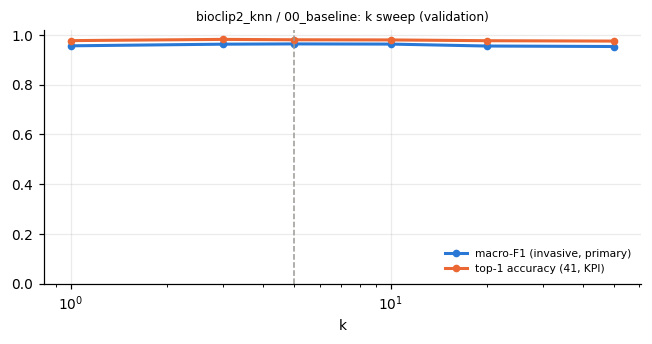

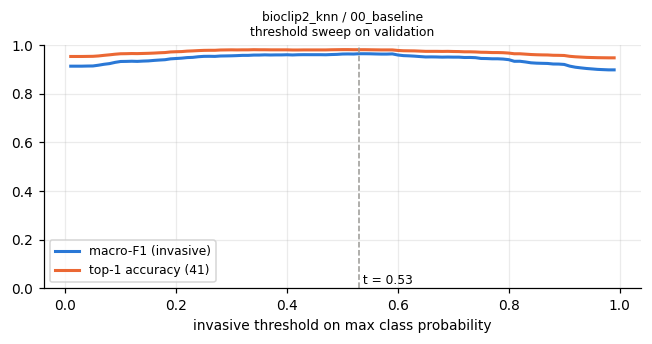

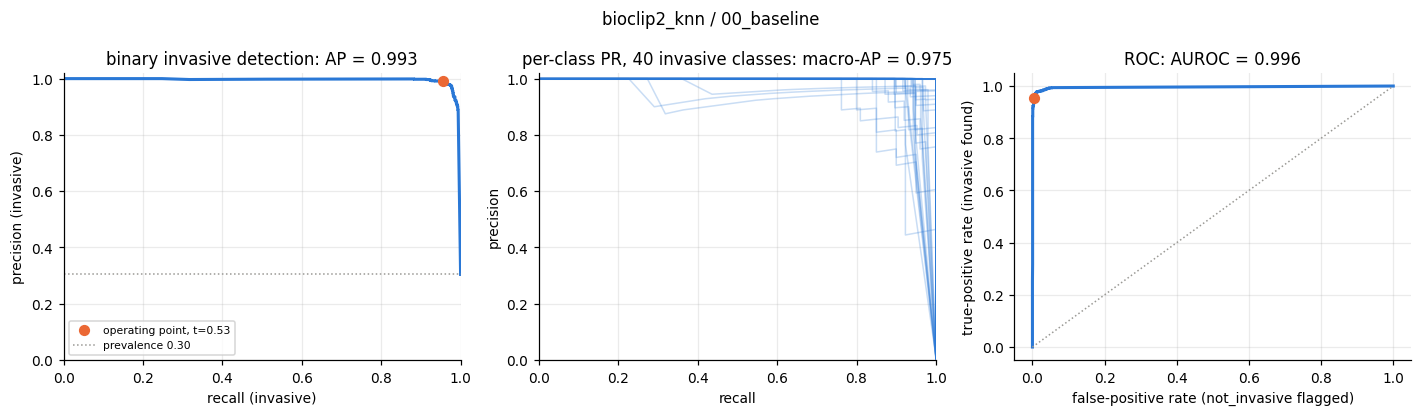

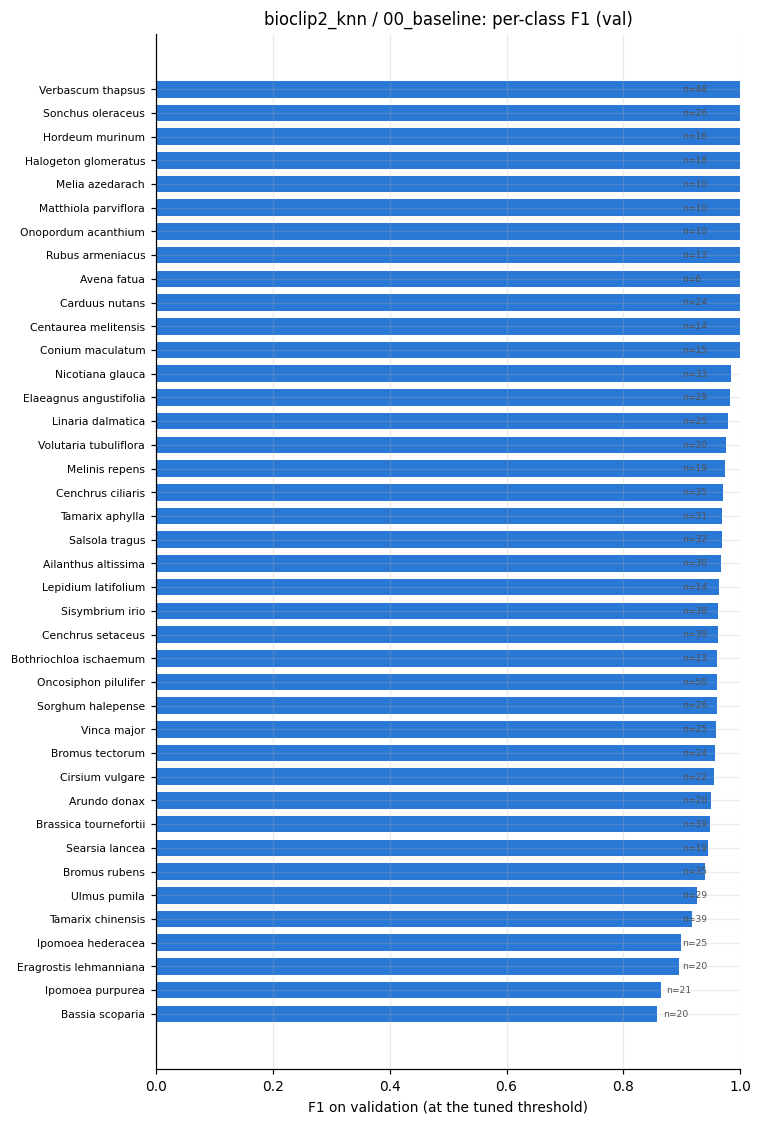

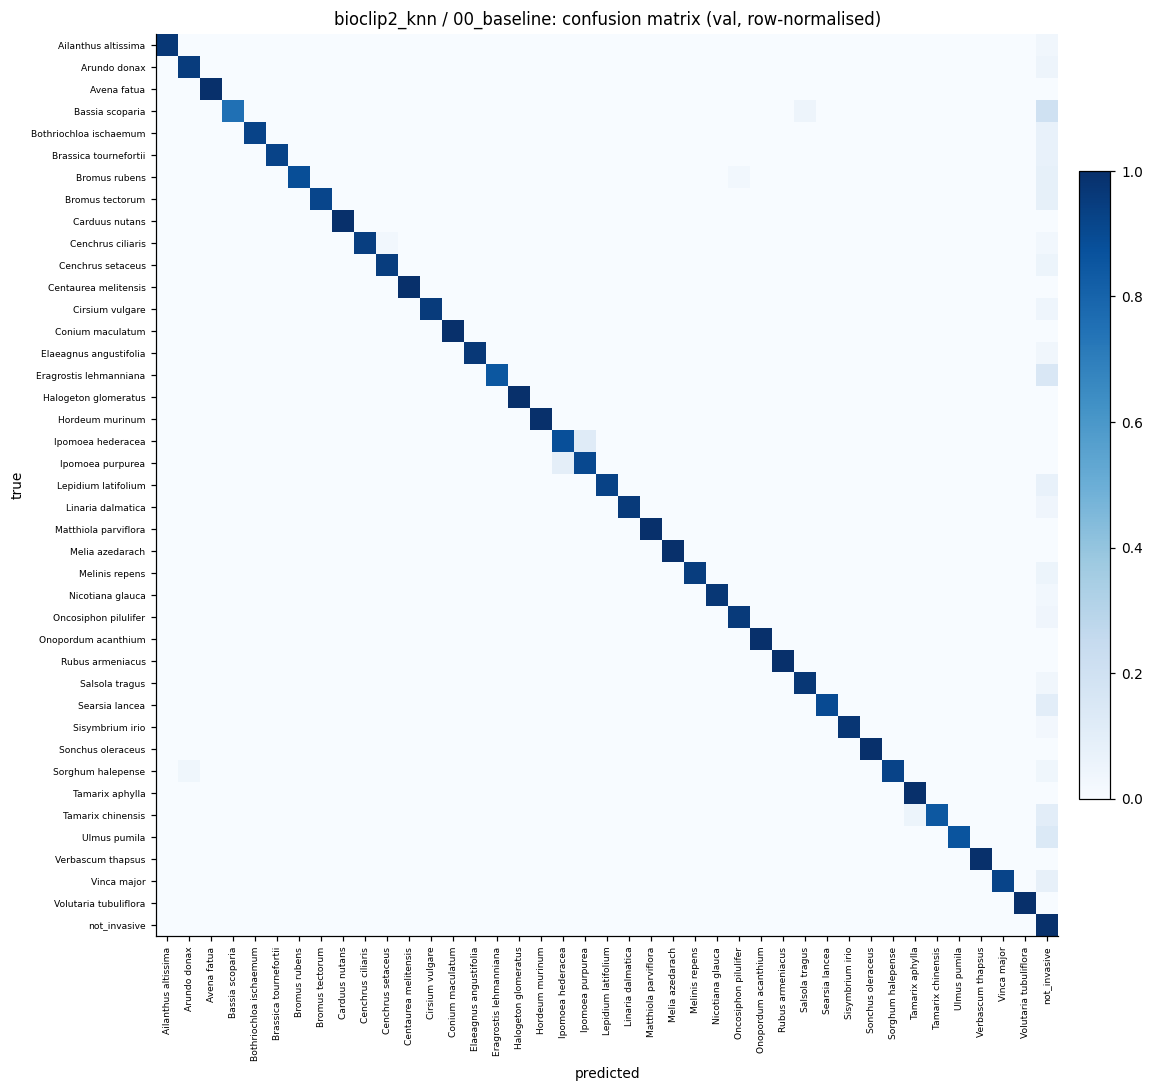

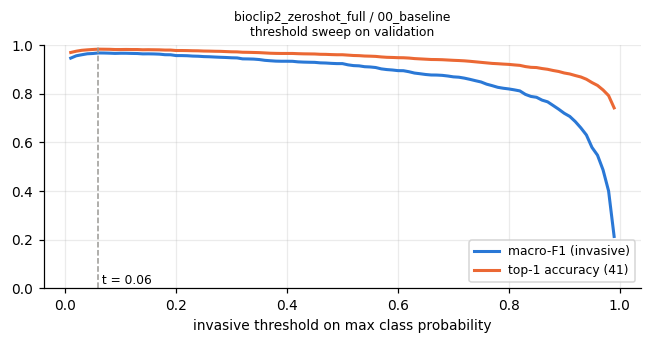

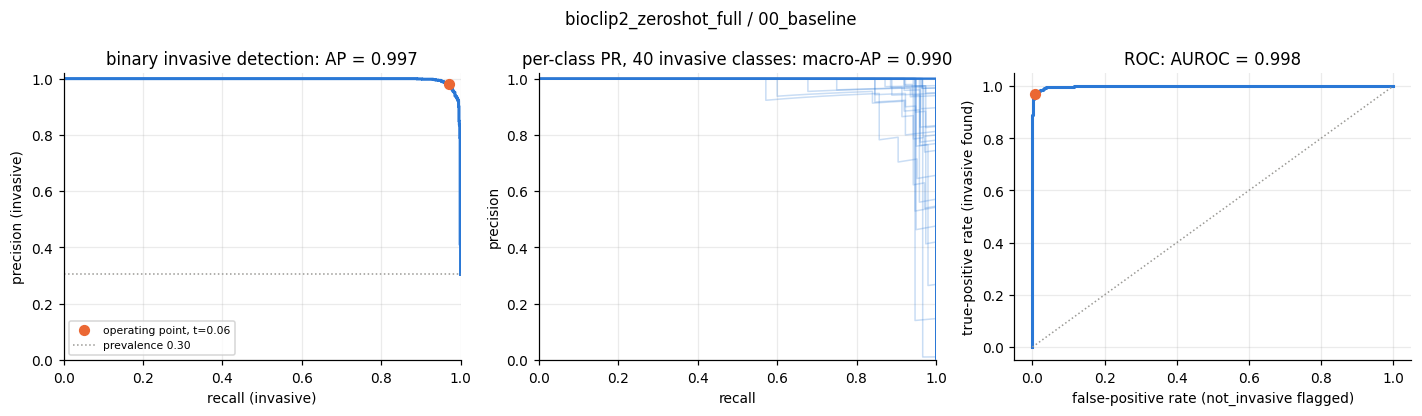

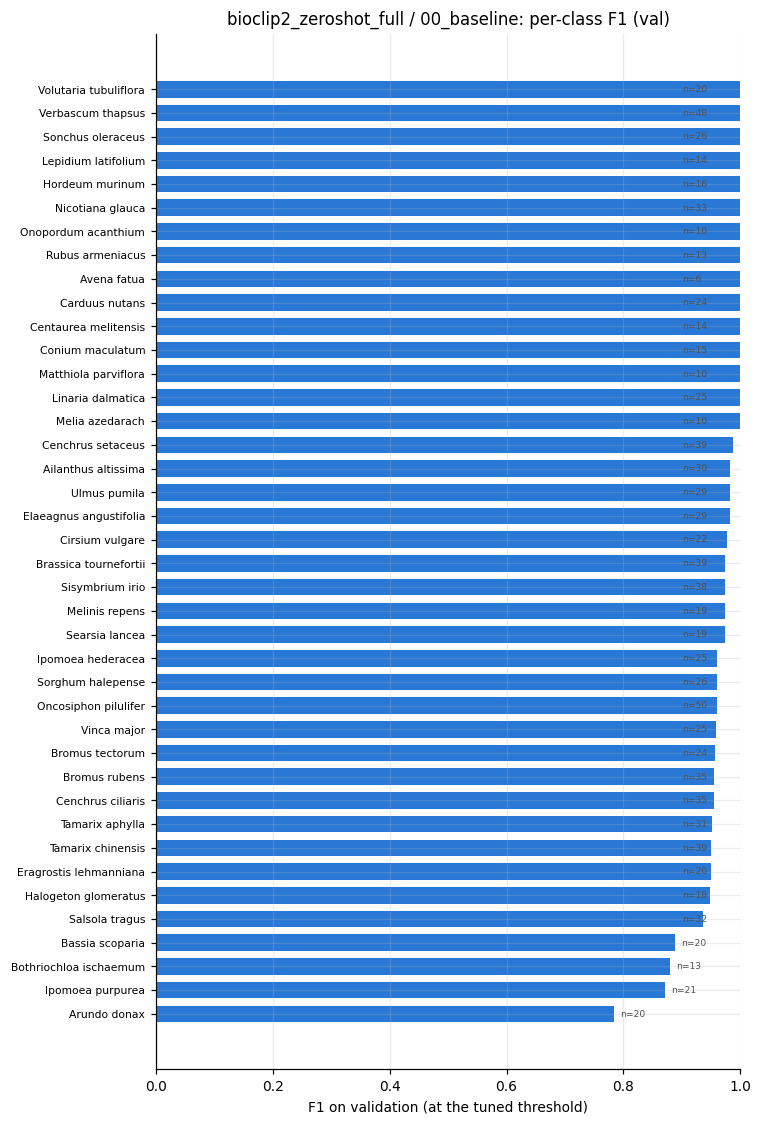

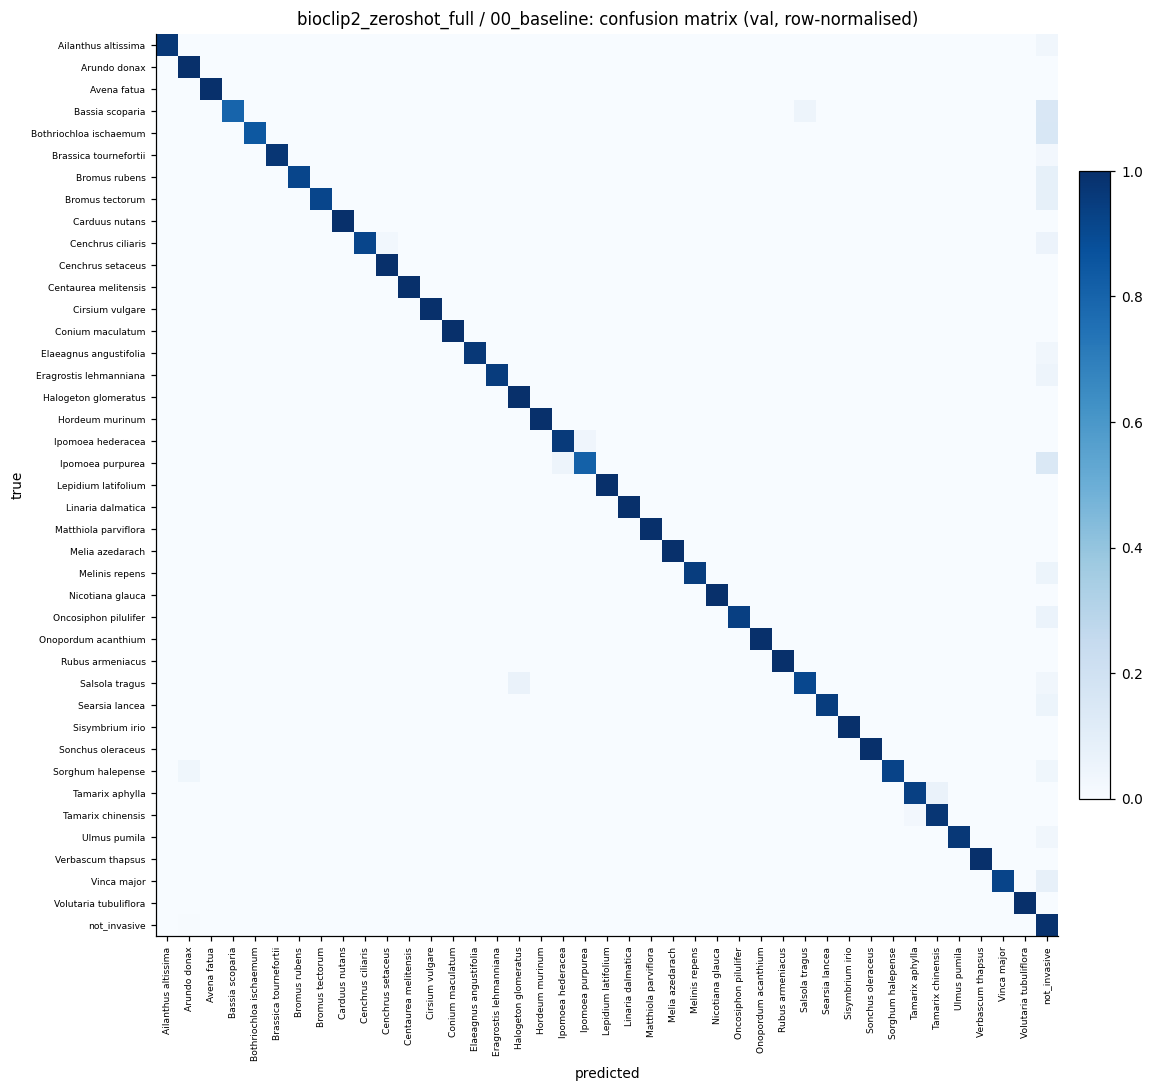

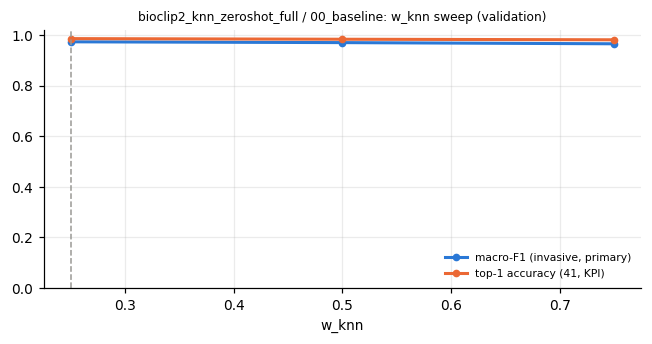

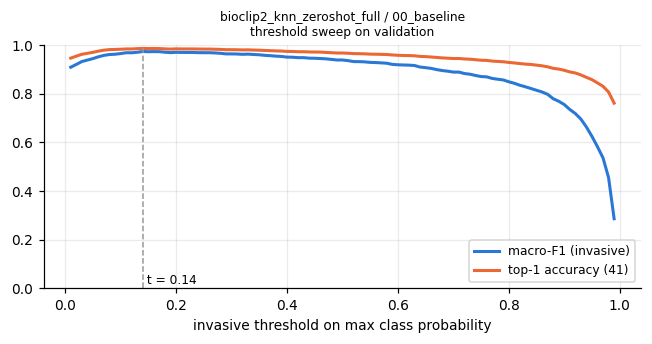

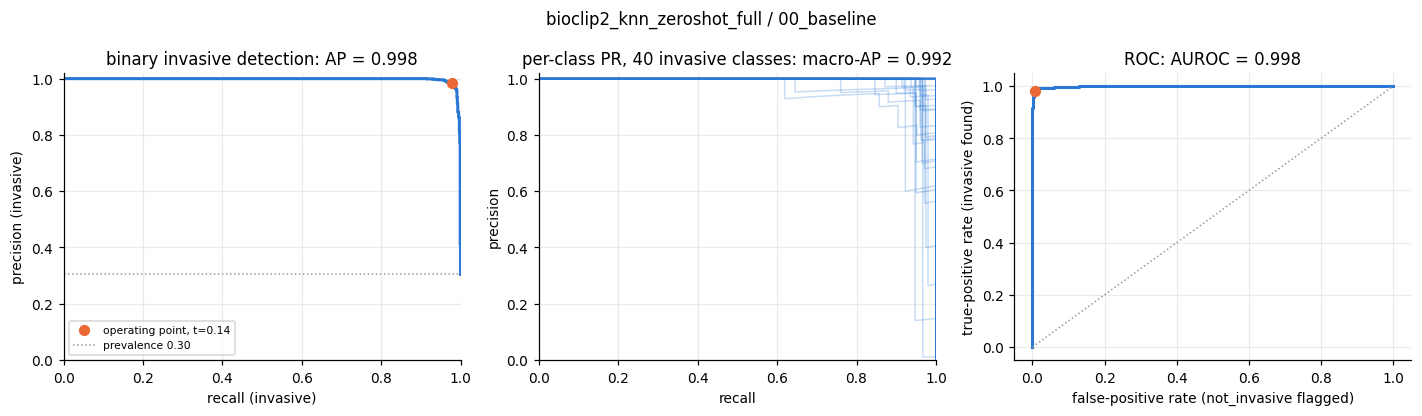

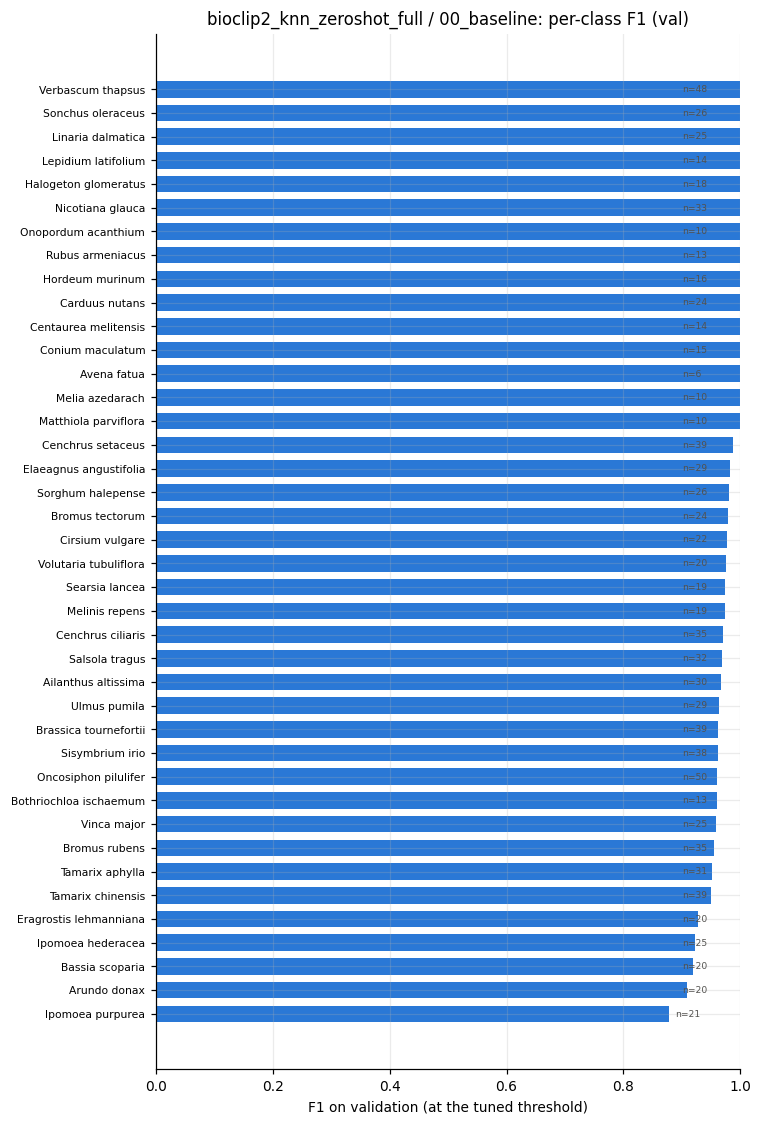

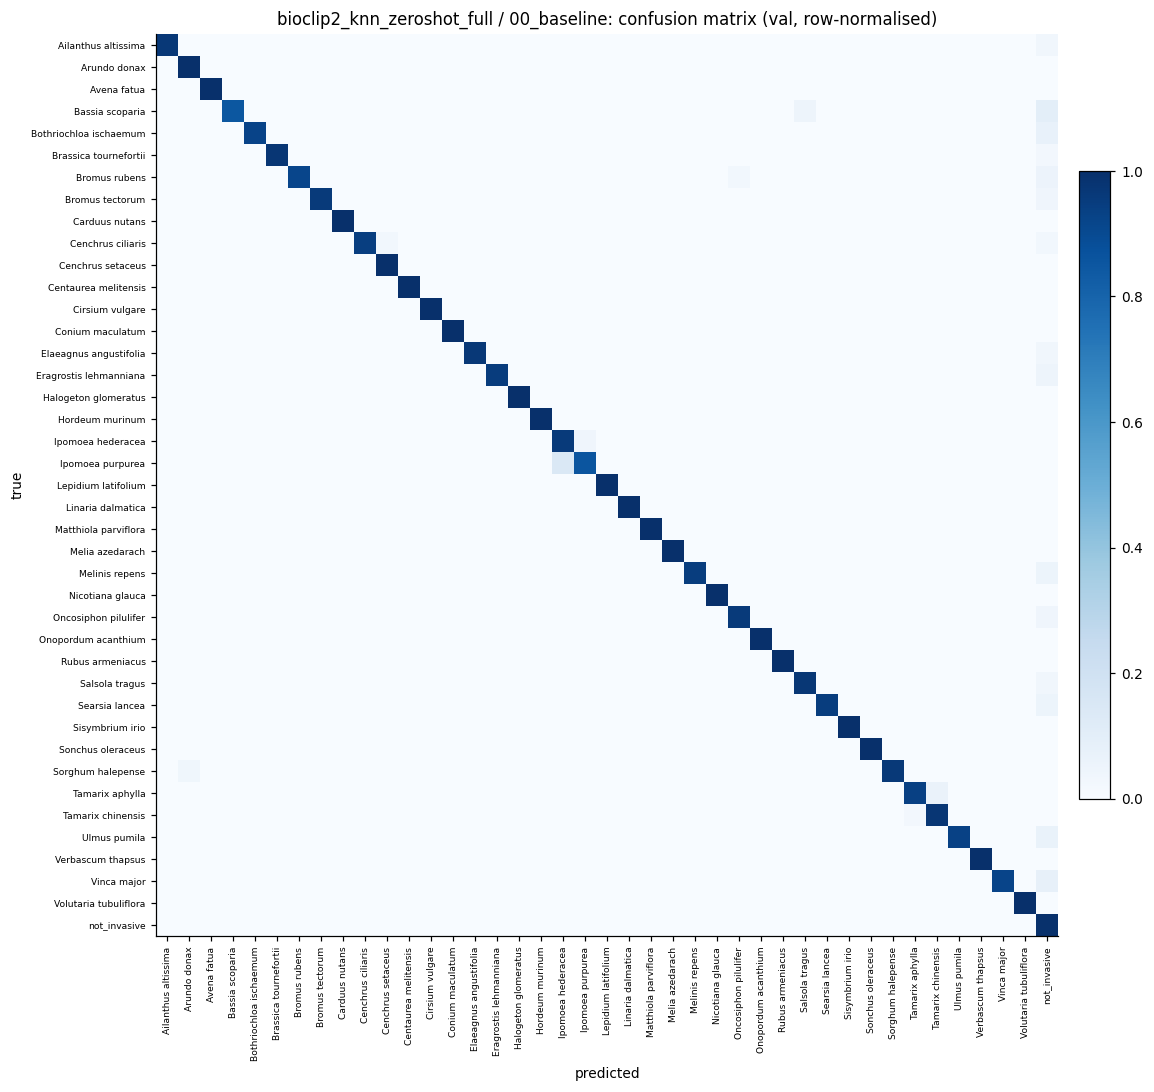

In [16]:
def save_family(key, probs, hist, sel_col, extra_cfg, artefacts, minutes, note):
    family = FAMILIES[key]; model_dir = RUNS_DIR / family; out_dir = model_dir / "00_baseline"; out_dir.mkdir(parents=True, exist_ok=True)
    m = compute_metrics(probs, y_va, None, THR)
    cfg = {**copy.deepcopy(BASE_CONFIG), "iteration": "00_baseline", "model_name": family, "backbone": BACKBONE, "overrides": {},
           "built_on_accepted": [], **extra_cfg}
    json.dump(cfg, open(out_dir / "config.json", "w"), indent=1, default=str)
    hist.to_csv(out_dir / "history.csv", index=False)
    best_i = int(hist.macro_f1_invasive.idxmax())
    summary = {"model": family, "iteration": "00_baseline", "best_epoch": best_i + 1, "epochs": len(hist), "tta_hflip": True,
               "train_minutes": FEATURE_MINUTES + minutes, "feature_minutes": FEATURE_MINUTES, **{k: v for k, v in extra_cfg.items() if np.isscalar(v)},
               **scalars(m)}
    json.dump({**summary, "per_class_f1": dict(zip(ALL_LABELS, m["per_class_f1"])), "per_class_ap": dict(zip(INVASIVE_CLASSES, m["per_class_ap"])),
               "labels": ALL_LABELS, "confusion_matrix": m["confusion_matrix"]}, open(out_dir / "metrics_final.json", "w"), indent=1, default=float)
    pd.DataFrame({"observation_id": val_df["observation_id"], "label": val_df["label"], "group": val_df["group"],
                  "scientific_name": val_df["scientific_name"], "pred": [ALL_LABELS[i] for i in m["_pred"]],
                  "max_prob": probs.max(1), "argmax_class": [INVASIVE_CLASSES[i] for i in probs.argmax(1)]}).to_csv(out_dir / "val_predictions.csv", index=False)
    if SAVE_WEIGHTS:
        joblib.dump({"backbone": BACKBONE, "labels": ALL_LABELS, "threshold": m["threshold"], "config": cfg, "logit_scale": LOGIT_SCALE, **artefacts},
                    out_dir / "best.joblib", compress=3)
    json.dump([{"name": "00_baseline", "decision": "accepted", "overrides": {}, "note": note, "macro_f1_invasive": m["macro_f1_invasive"],
                "top1_acc_all": m["top1_acc_all"], "when": datetime.datetime.now().isoformat(timespec="seconds")}],
              open(model_dir / "decisions.json", "w"), indent=1, default=str)
    ttl = f"{family} / 00_baseline"
    if len(hist) > 1:
        fig, ax = plt.subplots(figsize=(6, 3.2))
        ax.plot(hist[sel_col], hist.macro_f1_invasive, color=C_BLUE, lw=2, marker="o", ms=4, label="macro-F1 (invasive, primary)")
        ax.plot(hist[sel_col], hist.top1_acc_all, color=C_ORANGE, lw=2, marker="o", ms=4, label="top-1 accuracy (41, KPI)")
        ax.axvline(hist.loc[best_i, sel_col], color=C_GRAY, ls="--", lw=1); ax.set_xlabel(sel_col); ax.set_ylim(0, 1.02)
        if sel_col == "k": ax.set_xscale("log")
        ax.set_title(f"{ttl}: {sel_col} sweep (validation)", fontsize=8); ax.legend(fontsize=7, frameon=False, loc="lower right")
        fig.tight_layout(); fig.savefig(out_dir / f"{sel_col}_sweep.png"); plt.show()
    plot_threshold_sweep(m["_sweep"], m["threshold"], out_dir, f"{ttl}\nthreshold sweep on validation")
    plot_pr_roc(probs, y_va, m, out_dir, ttl)
    plot_per_class_f1(m, out_dir, val_df["label"].value_counts(), f"{ttl}: per-class F1 (val)")
    plot_confusion(m, out_dir, f"{ttl}: confusion matrix (val, row-normalised)")
    return m

f16 = lambda a: (a.numpy() if torch.is_tensor(a) else a).astype(np.float16)
knn_art = {"train_features": f16(F_tr), "train_y": y_tr.astype(np.int16), "k": K_BEST, "tau": KNN_TAU}
zs_art = {"text_embeddings": f16(TXT_FULL), "vocab_to_label": np.where(M_FULL.any(1), M_FULL.argmax(1), N_INVASIVE).astype(np.int16),
          "vocab_names": list(map(str, zv["vocab_label"])) + cand["class_name"].astype(str).tolist()}
RESULTS = {
    "knn": save_family("knn", P_knn[K_BEST], hist_knn, "k", {"method": "knn", "k": K_BEST, "tau": KNN_TAU, "k_grid": K_GRID}, knn_art,
                       KNN_MINUTES, f"kNN (k={K_BEST}) on frozen BioCLIP 2 features"),
    "zs": save_family("zs", P_zs, hist_zs, "vocab_size", {"method": "zero_shot", "prompt": "scientific", "vocab_size": len(TXT_FULL)}, zs_art,
                      ZS_MINUTES, f"BioCLIP 2 zero-shot, {len(TXT_FULL)}-name vocabulary"),
    "ens": save_family("ens", P_ens[W_BEST], hist_ens, "w_knn", {"method": "knn+zero_shot", "k": K_BEST, "tau": KNN_TAU, "w_knn": W_BEST,
                       "vocab_size": len(TXT_FULL)}, {**knn_art, **zs_art}, KNN_MINUTES + ZS_MINUTES, f"{W_BEST} kNN + {1 - W_BEST} zero-shot (full vocabulary)"),
}
RESULTS["logreg"] = json.load(open(PROBE_DIR / "metrics_final.json"))

## 12. Unknown species, rehearsed on val

The same draws as notebook 15 (Parts A and D): for each share of background species and each seed, those species are made unknown to **every** candidate at once. Their names leave the vocabulary, and their training photos leave the kNN index and the logistic regression's training set (refit at the chosen `C`). Their val photos stay. Hyperparameters and thresholds stay at the values chosen above, as they would in use. The 4,132 extras are never removed.

In [17]:
T = {k: (RESULTS[k]["threshold"]) for k in ["knn", "zs", "ens", "logreg"]}
rows = []; t0 = time.time()
for f in OPENSET_FRACS:
    for s in range(OPENSET_SEEDS):
        rng = np.random.default_rng(s)
        removed = rng.choice(BG, size=int(round(f * len(BG))), replace=False)
        keep_tr = ~np.isin(v_tr, removed); keep_voc = np.setdiff1d(np.arange(len(TXT_FULL)), removed)
        unseen = np.isin(v_va, removed); seen_bg = (y_va == N_INVASIVE) & ~unseen; is_inv = y_va < N_INVASIVE
        pk = tta(lambda Fq: knn_probs(F_tr[keep_tr], y_tr[keep_tr], Fq, K_BEST))
        pz = tta(lambda Fq: zs_probs(TXT_FULL[keep_voc], M_FULL[keep_voc], Fq))
        probs = {"knn": pk, "zs": pz, "ens": W_BEST * pk + (1 - W_BEST) * pz}
        if OPENSET_LOGREG:
            lr = fit_logreg(R_tr[keep_tr], y_tr[keep_tr], PROBE_C, BASE_CONFIG)
            probs["logreg"] = 0.5 * (predict_proba(lr, R_va) + predict_proba(lr, R_vf))
        for key, p in probs.items():
            pred = predict_not_invasive(p, T[key]); flagged = pred < N_INVASIVE
            rows.append({"candidate": key, "frac_removed": f, "seed": s, "n_unseen_images": int(unseen.sum()),
                         "false_alarm_unseen": flagged[unseen].mean(), "false_alarm_seen": flagged[seen_bg].mean(),
                         "invasive_recall": flagged[is_inv].mean(), "macro_f1_invasive": macro_f1_invasive(y_va, pred)})
        print(f"f = {f}, seed {s} done ({time.time() - t0:.0f}s)")
openset = pd.DataFrame(rows); openset.to_csv(OUT_ROBUST / "06_openset_candidates.csv", index=False)
open_mean = openset.groupby(["candidate", "frac_removed"]).mean(numeric_only=True).drop(columns="seed")
for col in ["false_alarm_unseen", "false_alarm_seen", "macro_f1_invasive"]:
    print(f"\n{col} (mean over {OPENSET_SEEDS} draws)"); display(open_mean[col].unstack(0).round(4))

f = 0.1, seed 0 done (11s)
f = 0.1, seed 1 done (18s)
f = 0.1, seed 2 done (26s)
f = 0.1, seed 3 done (32s)
f = 0.1, seed 4 done (40s)
f = 0.25, seed 0 done (46s)
f = 0.25, seed 1 done (52s)
f = 0.25, seed 2 done (59s)
f = 0.25, seed 3 done (64s)
f = 0.25, seed 4 done (71s)
f = 0.5, seed 0 done (76s)
f = 0.5, seed 1 done (80s)
f = 0.5, seed 2 done (85s)
f = 0.5, seed 3 done (90s)
f = 0.5, seed 4 done (94s)

false_alarm_unseen (mean over 5 draws)


candidate,ens,knn,logreg,zs
frac_removed,,,,
0.10,0.0982,0.0939,0.0495,0.0458
0.25,0.1217,0.1190,0.0641,0.0409
0.50,0.1467,0.1474,0.0671,0.0398



false_alarm_seen (mean over 5 draws)


candidate,ens,knn,logreg,zs
frac_removed,,,,
0.10,0.0071,0.0040,0.0090,0.0076
0.25,0.0069,0.0042,0.0092,0.0068
0.50,0.0082,0.0052,0.0094,0.0081



macro_f1_invasive (mean over 5 draws)


candidate,ens,knn,logreg,zs
frac_removed,,,,
0.10,0.9627,0.9532,0.9436,0.9630
0.25,0.9401,0.9314,0.9346,0.9584
0.50,0.8999,0.8895,0.9218,0.9492


## 13. Summary: which BioCLIP 2 candidate to put forward

Paired bootstrap on val (the same resampled rows for every candidate) gives the 95% interval of each candidate's macro-F1 difference from the best one. Candidates whose interval contains 0 are **tied on val**; among those, the unknown-species false-alarm rate is the deciding number. This notebook only reports; `18_final_model_comparison.ipynb` makes the team's selection.

,macro_f1_invasive,top1_acc_all,bin_precision_invasive,bin_recall_invasive,threshold,delta_vs_best,delta_ci_low,delta_ci_high,tied_with_best,false_alarm_unknown_10pct,false_alarm_unknown_25pct,false_alarm_unknown_50pct,false_alarm_known
candidate,,,,,,,,,,,,,
logreg_bioclip2,0.9511,0.9746,0.9820,0.9450,0.14,-0.0217,-0.0328,-0.0119,False,0.0495,0.0641,0.0671,0.0076
bioclip2_knn,0.9635,0.9802,0.9905,0.9552,0.53,-0.0093,-0.0174,-0.0023,False,0.0939,0.1190,0.1474,0.0040
bioclip2_zeroshot_full,0.9668,0.9823,0.9815,0.9705,0.06,-0.0061,-0.0142,0.0018,True,0.0458,0.0409,0.0398,0.0080
bioclip2_knn_zeroshot_full,0.9728,0.9854,0.9836,0.9796,0.14,0.0000,0.0000,0.0000,True,0.0982,0.1217,0.1467,0.0071


tied with the best on val macro-F1: ['bioclip2_zeroshot_full', 'bioclip2_knn_zeroshot_full']
lowest unknown-species false alarms among them (false_alarm_unknown_25pct): bioclip2_zeroshot_full


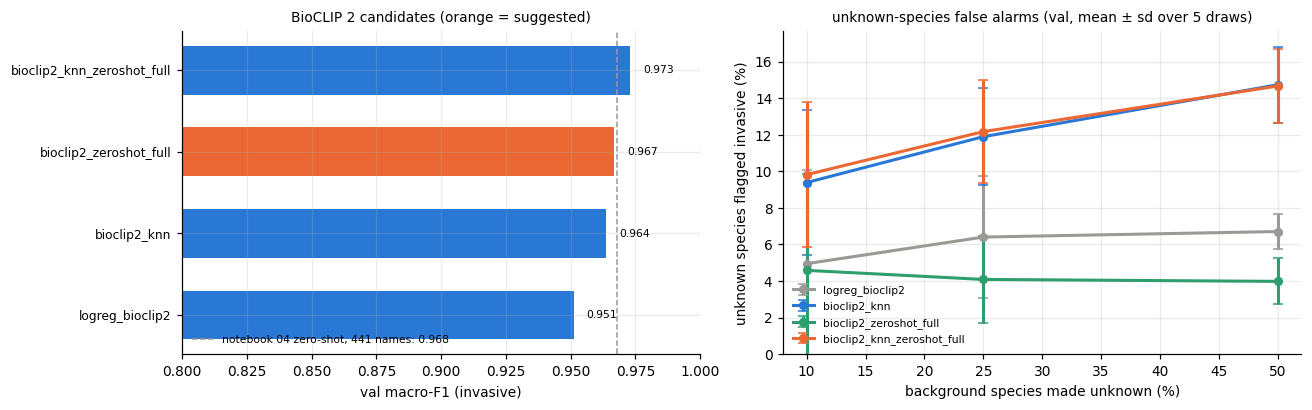

In [18]:
NAMES = {"logreg": f"logreg_{BACKBONE}", "knn": FAMILIES["knn"], "zs": FAMILIES["zs"], "ens": FAMILIES["ens"]}
preds = {}
for key, fam in NAMES.items():
    vp = pd.read_csv(RUNS_DIR / fam / "00_baseline" / "val_predictions.csv")
    assert (vp.observation_id.to_numpy() == val_df.observation_id.to_numpy()).all()
    preds[key] = vp.pred.map(CLASS_TO_IDX).to_numpy()

def fast_macro_f1(y, pred, n=N_INVASIVE + 1):
    cm = np.bincount(y * n + pred, minlength=n * n).reshape(n, n); tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    return np.divide(2 * tp, 2 * tp + fp + fn, out=np.zeros(n), where=(2 * tp + fp + fn) > 0)[:N_INVASIVE].mean()
point = {k: fast_macro_f1(y_va, p) for k, p in preds.items()}; leader = max(point, key=point.get)
rng = np.random.default_rng(0); boots = {k: [] for k in preds}
for _ in range(N_BOOT):
    i = rng.integers(0, len(y_va), len(y_va))
    for k, p in preds.items(): boots[k].append(fast_macro_f1(y_va[i], p[i]))
summ = []
for key, fam in NAMES.items():
    m = json.load(open(RUNS_DIR / fam / "00_baseline" / "metrics_final.json"))
    d = np.array(boots[key]) - np.array(boots[leader]); lo, hi = np.percentile(d, [2.5, 97.5])
    om = open_mean.loc[key] if key in open_mean.index.get_level_values(0) else None
    summ.append({"candidate": fam, "macro_f1_invasive": m["macro_f1_invasive"], "top1_acc_all": m["top1_acc_all"],
                 "bin_precision_invasive": m["bin_precision_invasive"], "bin_recall_invasive": m["bin_recall_invasive"], "threshold": m["threshold"],
                 "delta_vs_best": point[key] - point[leader], "delta_ci_low": lo, "delta_ci_high": hi, "tied_with_best": lo <= 0 <= hi,
                 **({f"false_alarm_unknown_{int(f * 100)}pct": om.loc[f, "false_alarm_unseen"] for f in OPENSET_FRACS} if om is not None else {}),
                 "false_alarm_known": float((preds[key][y_va == N_INVASIVE] < N_INVASIVE).mean())})
summ = pd.DataFrame(summ).set_index("candidate"); summ.to_csv(OUT_ROBUST / "06_candidates_summary.csv")
display(summ.round(4))
zs04 = json.load(open(ZS_DIR / "taxonomic" / "metrics_final.json"))["macro_f1_invasive"] if (ZS_DIR / "taxonomic" / "metrics_final.json").exists() else None
tied = summ[summ.tied_with_best]
col = f"false_alarm_unknown_{int(OPENSET_FRACS[1] * 100)}pct"
pick = tied[col].idxmin() if col in tied else tied.macro_f1_invasive.idxmax()
print(f"tied with the best on val macro-F1: {list(tied.index)}\nlowest unknown-species false alarms among them ({col}): {pick}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]; order = summ.macro_f1_invasive.sort_values().index; yy = np.arange(len(order))
ax.barh(yy, summ.loc[order, "macro_f1_invasive"], height=0.6, color=[C_ORANGE if n == pick else C_BLUE for n in order])
for i_, n in enumerate(order): ax.text(summ.loc[n, "macro_f1_invasive"] + 0.005, i_, f"{summ.loc[n, 'macro_f1_invasive']:.3f}", va="center", fontsize=7)
if zs04: ax.axvline(zs04, color=C_GRAY, ls="--", lw=1, label=f"notebook 14 zero-shot, 441 names: {zs04:.3f}"); ax.legend(fontsize=7, frameon=False, loc="lower left")
ax.set_yticks(yy); ax.set_yticklabels(order, fontsize=8); ax.set_xlim(min(0.8, summ.macro_f1_invasive.min() - 0.05), 1.0); ax.set_xlabel("val macro-F1 (invasive)")
ax.set_title("BioCLIP 2 candidates (orange = suggested)", fontsize=9)
ax = axes[1]
for key, c in zip(["logreg", "knn", "zs", "ens"], [C_GRAY, C_BLUE, "#2f9e6e", C_ORANGE]):
    if key not in open_mean.index.get_level_values(0): continue
    g = openset[openset.candidate == key].groupby("frac_removed").false_alarm_unseen; mu, sd = g.mean(), g.std()
    ax.errorbar(mu.index * 100, mu * 100, yerr=sd * 100, color=c, lw=2, marker="o", ms=5, capsize=3, label=NAMES[key])
ax.set_ylim(bottom=0); ax.set_xlabel("background species made unknown (%)"); ax.set_ylabel("unknown species flagged invasive (%)")
ax.set_title(f"unknown-species false alarms (val, mean ± sd over {OPENSET_SEEDS} draws)", fontsize=9); ax.legend(fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig(OUT_ROBUST / "06_candidates_summary.png"); plt.show()

## How to read this
- **Section 7 vs the other benchmark probes:** `logreg_bioclip2` is the like-for-like row next to `logreg_dinov3_vits16` etc.: same recipe, different backbone.
- **Section 13, left:** differences of about 0.01 or less are within val noise (about 24 val images per invasive class). Treat tied candidates as equal on this metric.
- **Section 13, right:** the share of photos of species the model was never told about that get flagged invasive. In the field most species are not in our 441, so this is the more relevant number among tied candidates.
- **`test.csv` and `test_unseen.csv` stay untouched.** The final notebook scores the chosen candidate on them once. kNN and zero-shot need no retraining for that: `best.joblib` holds the index, the vocabulary and the threshold.